# TP2 — Optimización del moveset ofensivo de Charizard con un Algoritmo Genético

**Grupo 6 — Inteligencia Artificial (UTN FRBA), entrega final.**

Este notebook es una demostración didáctica y ejecutable. No reimplementa nada: importa los módulos de
`src/charizard_ga`, que son los mismos que usan la consola (`scripts/run_ga.py`), el lote de experimentos
(`scripts/run_experiments.py`) y el generador del informe. Todos los números se calculan al ejecutar las celdas.

Contenido: 1) datos, 2) tabla de tipos, 3) cromosoma y función de aptitud, 4) operadores genéticos,
5) una corrida completa con DEAP, 6) resultados del lote y comparación con la enumeración exhaustiva.

In [1]:
# Configuración: se ubica la carpeta raíz del proyecto (la que contiene config/ y src/) sin rutas absolutas.
import sys
from pathlib import Path

ROOT = Path.cwd()
while not ((ROOT / "config").is_dir() and (ROOT / "src").is_dir()):
    if ROOT.parent == ROOT:
        raise RuntimeError("No se encontró la raíz del proyecto")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import math
import pandas as pd
import matplotlib.pyplot as plt

from charizard_ga.data import load_catalog, load_metadata, TYPE_ORDER
from charizard_ga.config import load_experiments
from charizard_ga.fitness import components, contributions, fitness, validate_moveset, weighted_fitness, Evaluator
from charizard_ga.ga import run_ga, describe_solution
from charizard_ga.baselines import exhaustive_table, exhaustive_optimum

pd.set_option("display.width", 160)
print("Raíz del proyecto:", ROOT.name)

Raíz del proyecto: entrega_final


## 1. Datos

Catálogo definitivo: movimientos que Charizard aprende en **Pokémon Escarlata/Púrpura** (grupo de versiones
`scarlet-violet`, Gen 9), según PokéAPI fijada por commit y verificada contra Pokémon Showdown. Se excluyen
movimientos de estado y los casos que la función aprobada no puede representar (potencia o precisión no
numéricas, golpes múltiples). Ver `data/FUENTES_DATOS.md`.

In [2]:
catalog = load_catalog()
meta = load_metadata()
print(f"M = {catalog.M} movimientos; C(M,4) = {math.comb(catalog.M, 4):,} movesets posibles")
print("Potencia máxima del catálogo (normaliza P):", catalog.power_max)
print("Versión del dataset:", catalog.dataset_version, "| excluidos por motivo:", meta["conteos"]["excluidos_por_motivo"])
cat_df = pd.DataFrame([vars(m) for m in catalog.moves.values()])
cat_df[["nombre_es", "tipo_es", "potencia", "precision", "categoria", "stab"]].sort_values(["tipo_es", "potencia"]).head(12)

M = 53 movimientos; C(M,4) = 292,825 movesets posibles
Potencia máxima del catálogo (normaliza P): 150
Versión del dataset: 6557b19f60a8 | excluidos por motivo: {'POTENCIA_NO_NUMERICA': 3, 'ESTADO': 17, 'PRECISION_NO_NUMERICA': 2}


,nombre_es,tipo_es,potencia,precision,categoria,stab
21,Garra Metal,Acero,50,95,physical,False
20,Cola Férrea,Acero,100,75,physical,False
19,Dragoaliento,Dragón,60,100,special,False
47,Cola Dragón,Dragón,60,90,physical,False
49,Vasto Impacto,Dragón,60,100,physical,False
33,Garra Dragón,Dragón,80,100,physical,False
36,Pulso Dragón,Dragón,85,100,special,False
37,Carga Dragón,Dragón,100,75,physical,False
18,Enfado,Dragón,120,100,physical,False
1,Puño Trueno,Eléctrico,75,100,physical,False


## 2. Tabla de efectividad

Orientación explícita: **filas = tipo atacante, columnas = tipo defensor**. La cobertura C(x) cuenta los
tipos defensores para los que algún movimiento tiene multiplicador mayor que 1.

In [3]:
chart = pd.DataFrame(catalog.chart).T.loc[list(TYPE_ORDER), list(TYPE_ORDER)]
print("Fuego -> Planta:", chart.loc["fire", "grass"], "| Planta -> Fuego:", chart.loc["grass", "fire"])
print("Eléctrico -> Tierra:", chart.loc["electric", "ground"], "| Tierra -> Eléctrico:", chart.loc["ground", "electric"])
chart.loc[["fire", "flying", "ground", "fighting"]]

Fuego -> Planta: 2.0 | Planta -> Fuego: 0.5
Eléctrico -> Tierra: 0.0 | Tierra -> Eléctrico: 2.0


,normal,fire,water,electric,grass,ice,fighting,poison,ground,flying,psychic,bug,rock,ghost,dragon,dark,steel,fairy
fire,1.0,0.5,0.5,1.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0,0.5,1.0,0.5,1.0,2.0,1.0
flying,1.0,1.0,1.0,0.5,2.0,1.0,2.0,1.0,1.0,1.0,1.0,2.0,0.5,1.0,1.0,1.0,0.5,1.0
ground,1.0,2.0,1.0,2.0,0.5,1.0,1.0,2.0,1.0,0.0,1.0,0.5,2.0,1.0,1.0,1.0,2.0,1.0
fighting,2.0,1.0,1.0,1.0,1.0,2.0,1.0,0.5,1.0,0.5,0.5,0.5,2.0,0.0,1.0,2.0,2.0,0.5


## 3. Cromosoma y función de aptitud

Un individuo es una lista de **cuatro IDs de movimientos distintos**. El orden no cambia el significado.

F(x) = 100 × (wC·C + wP·P + wA·A + wS·S + wD·D), con componentes en [0, 1]. Perfil base R1:
wC = 0,40; wP = 0,20; wA = 0,15; wS = 0,15; wD = 0,10.

Ejemplo de la entrega parcial: Lanzallamas, Tajo Aéreo, Pulso Dragón, Rayo Solar.

In [4]:
exps = load_experiments()
w_base = exps["profiles"]["R1"]
example = [catalog.by_slug(s) for s in ["flamethrower", "air-slash", "dragon-pulse", "solar-beam"]]
comp = components(example, catalog)
print("Movimientos:", catalog.names(example))
print("Tipos cubiertos (", len(comp.covered), "):", [catalog.type_es[t] for t in comp.covered])
print({k: round(v, 6) for k, v in zip("CPASD", comp.as_tuple())})
print("Aportes:", {k: round(v, 4) for k, v in contributions(comp, w_base).items()})
print("F(x) =", round(fitness(example, catalog, w_base), 6))

Movimientos: ['Lanzallamas', 'Tajo Aéreo', 'Pulso Dragón', 'Rayo Solar']
Tipos cubiertos ( 9 ): ['Agua', 'Planta', 'Hielo', 'Lucha', 'Tierra', 'Bicho', 'Roca', 'Dragón', 'Acero']
{'C': 0.5, 'P': 0.616667, 'A': 0.9875, 'S': 0.5, 'D': 1.0}
Aportes: {'C': 20.0, 'P': 12.3333, 'A': 14.8125, 'S': 7.5, 'D': 10.0}
F(x) = 64.645833


In [5]:
# Restricciones duras: aptitud 0 para individuos inválidos.
a, b, c, d = example
for label, ms in {"3 movimientos": [a, b, c], "repetido": [a, a, b, c], "fuera del catálogo (Danza Espada)": [a, b, c, 14]}.items():
    print(f"{label:35s} -> válido={validate_moveset(ms, catalog)[0]}, F={fitness(ms, catalog, w_base)}")
# Invariancia frente a permutaciones del mismo moveset.
import itertools
print("Valores distintos entre las 24 permutaciones:", len({fitness(list(p), catalog, w_base) for p in itertools.permutations(example)}))

3 movimientos                       -> válido=False, F=0.0
repetido                            -> válido=False, F=0.0
fuera del catálogo (Danza Espada)   -> válido=False, F=0.0
Valores distintos entre las 24 permutaciones: 1


## 4. Operadores genéticos

- **Inicialización**: 4 movimientos muestreados sin reemplazo.
- **Selección**: torneo de tamaño 3 (`tools.selTournament`) o ruleta (`tools.selRoulette`, con selección uniforme si todas las aptitudes valen 0).
- **Cruza** (por pareja, p = 0,80): uniforme con intercambio por posición p = 0,5 (`tools.cxUniform`) o de un punto (`tools.cxOnePoint`), seguidas de **reparación** de duplicados.
- **Mutación** (por individuo, p = 0,10): reemplaza un gen al azar por un movimiento ausente.
- **Reemplazo** generacional con **elitismo** de 2 individuos.

Demostración de la reparación: dos padres que comparten un movimiento en posiciones distintas.

In [6]:
import random
from charizard_ga.ga import ensure_deap_types, INDIVIDUAL_CLASS
from charizard_ga.operators import cx_uniform_repair, mut_replace_one, OperatorCounters
from deap import creator

ensure_deap_types()                      # se puede reejecutar sin advertencias de creator.create
Ind = getattr(creator, INDIVIDUAL_CLASS)
eq, hur, fb, fl, cr = (catalog.by_slug(s) for s in ["earthquake", "hurricane", "focus-blast", "flare-blitz", "crunch"])
from deap import tools
from charizard_ga.operators import repair_duplicates
counters = OperatorCounters()
p1, p2 = Ind([eq, hur, fb, fl]), Ind([cr, eq, a, b])   # Terremoto está en la posición 0 de p1 y en la 1 de p2
print("Padres:", catalog.names(p1), "x", catalog.names(p2))
# Se busca la primera semilla cuya cruza uniforme genera un duplicado, para mostrar la reparación paso a paso.
for seed in range(100):
    random.seed(seed)
    c1, c2 = Ind(p1), Ind(p2)
    tools.cxUniform(c1, c2, 0.5)
    if len(set(c1)) < 4 or len(set(c2)) < 4:
        break
print(f"Semilla {seed}, cruza uniforme SIN reparar:", catalog.names(c1), "|", catalog.names(c2))
pool = list(dict.fromkeys(list(p1) + list(p2)))       # genes disponibles de ambos padres
fixed = [repair_duplicates(child, pool, catalog.ids) for child in (c1, c2)]
print("Después de reparar:", catalog.names(c1), "|", catalog.names(c2), "| posiciones reparadas:", fixed)
print("¿Hijos válidos?", validate_moveset(c1, catalog)[0], validate_moveset(c2, catalog)[0])
m = Ind(p1); mut_replace_one(m, catalog.ids, counters)
print("Mutación:", catalog.names(p1), "->", catalog.names(m))

Padres: ['Terremoto', 'Vendaval', 'Onda Certera', 'Envite Ígneo'] x ['Triturar', 'Terremoto', 'Lanzallamas', 'Tajo Aéreo']
Semilla 1, cruza uniforme SIN reparar: ['Triturar', 'Vendaval', 'Onda Certera', 'Tajo Aéreo'] | ['Terremoto', 'Terremoto', 'Lanzallamas', 'Envite Ígneo']
Después de reparar: ['Triturar', 'Vendaval', 'Onda Certera', 'Tajo Aéreo'] | ['Terremoto', 'Tajo Aéreo', 'Lanzallamas', 'Envite Ígneo'] | posiciones reparadas: [0, 1]
¿Hijos válidos? True True
Mutación: ['Terremoto', 'Vendaval', 'Onda Certera', 'Envite Ígneo'] -> ['Terremoto', 'Vendaval', 'Onda Certera', 'Sofoco']


## 5. Corrida completa con DEAP (R1, semilla 42)

Se ejecuta la corrida principal R1 y se comprueba que reproduce exactamente el log guardado por el lote
(`results/runs/R1/seed_42_log.csv`).

In [7]:
exp_r1 = next(c for c in exps["configs"] if c.config_id == "R1")
print("Parámetros:", exp_r1.ga.to_dict())
res = run_ga(catalog, exp_r1.weights, exp_r1.ga, seed=42, config_id="R1", verbose=True, print_every=40)
saved = pd.read_csv(ROOT / "results" / "runs" / "R1" / "seed_42_log.csv")
new = pd.DataFrame(res.log)
same = new[["aptitud_max", "aptitud_media", "mejor_acumulada"]].equals(saved[["aptitud_max", "aptitud_media", "mejor_acumulada"]])
print("¿Coincide con el log guardado?", same)
sol = describe_solution(res.best_moveset, catalog, exp_r1.weights, w_base)
pd.DataFrame(sol["movimientos"])[["nombre_es", "tipo_es", "potencia", "precision", "categoria", "stab"]]

Parámetros: {'population_size': 100, 'generations': 200, 'selection': 'tournament', 'tournament_size': 3, 'crossover': 'uniform', 'cx_prob': 0.8, 'cx_indpb': 0.5, 'mutation_prob': 0.1, 'elitism': 2, 'stop_criterion': 'generations'}
gen   0 | max 69.3194 | media 55.4363 | mejor acumulada 69.3194 | distintas 100 | mejor: earthquake|brick-break|flare-blitz|hurricane
gen  40 | max 72.7847 | media 71.9837 | mejor acumulada 72.7847 | distintas  11 | mejor: fly|solar-beam|earthquake|focus-punch
gen  80 | max 72.7847 | media 72.3765 | mejor acumulada 72.7847 | distintas   9 | mejor: fly|solar-beam|earthquake|focus-punch
gen 120 | max 72.7847 | media 72.3118 | mejor acumulada 72.7847 | distintas  10 | mejor: fly|solar-beam|earthquake|focus-punch


gen 160 | max 72.7847 | media 71.7197 | mejor acumulada 72.7847 | distintas  16 | mejor: fly|solar-beam|earthquake|focus-punch


gen 200 | max 72.7847 | media 72.3088 | mejor acumulada 72.7847 | distintas   9 | mejor: fly|solar-beam|earthquake|focus-punch


¿Coincide con el log guardado? True


,nombre_es,tipo_es,potencia,precision,categoria,stab
0,Vuelo,Volador,90,95,physical,True
1,Rayo Solar,Planta,120,100,special,False
2,Terremoto,Tierra,100,100,physical,False
3,Puño Certero,Lucha,150,100,physical,False


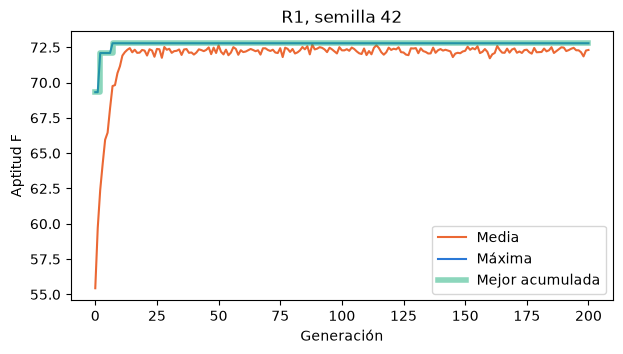

Mejor de la corrida: F = 72.784722 en la generación 7; evaluaciones solicitadas 16216, efectivas 705


In [8]:
log = pd.DataFrame(res.log)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(log.generacion, log.aptitud_media, label="Media", color="#eb6834")
ax.plot(log.generacion, log.aptitud_max, label="Máxima", color="#2a78d6")
ax.step(log.generacion, log.mejor_acumulada, where="post", label="Mejor acumulada", color="#1baf7a", alpha=0.5, linewidth=4)
ax.set_xlabel("Generación"); ax.set_ylabel("Aptitud F"); ax.legend(); ax.set_title("R1, semilla 42")
plt.show()
print(f"Mejor de la corrida: F = {res.best_fitness:.6f} en la generación {res.best_generation}; "
      f"evaluaciones solicitadas {res.evals_requested}, efectivas {res.evals_effective}")

## 6. Resultados del lote y referencia exacta

El lote ejecutó 8 configuraciones × 10 semillas. Como el espacio tiene 292.825 combinaciones, también se
puede **enumerar completo** con la misma función: eso da el óptimo demostrado de cada perfil y permite medir
la brecha del AG. Que la enumeración sea viable es un resultado en sí mismo (ver Discusión del informe).

In [9]:
summary = pd.read_csv(ROOT / "results" / "summary_configs.csv")
quality = pd.read_csv(ROOT / "results" / "quality_assessment.csv")
summary[["config_id", "aptitud_media", "aptitud_desvio", "aptitud_min", "aptitud_max", "generacion_encontrada_media", "moveset_modal"]].merge(
    quality[["config_id", "replicas_alcanzan_optimo"]], on="config_id")

,config_id,aptitud_media,aptitud_desvio,aptitud_min,aptitud_max,generacion_encontrada_media,moveset_modal,replicas_alcanzan_optimo
0,R1,72.784722,0.0,72.784722,72.784722,19.5,fly|solar-beam|earthquake|focus-punch,10
1,R2,75.958333,0.0,75.958333,75.958333,31.2,fly|solar-beam|earthquake|focus-punch,10
2,R3,79.500000,0.0,79.500000,79.500000,10.2,hyper-beam|solar-beam|focus-punch|blast-burn,10
3,R4,81.555556,0.0,81.555556,81.555556,17.0,fly|solar-beam|earthquake|focus-punch,10
4,R5,72.152778,0.0,72.152778,72.152778,29.8,fly|earthquake|focus-punch|blast-burn,10
5,OP-RUL,72.784722,0.0,72.784722,72.784722,56.9,fly|solar-beam|earthquake|focus-punch,10
6,OP-1P,72.784722,0.0,72.784722,72.784722,22.7,fly|solar-beam|earthquake|focus-punch,10
7,OP-MUT20,72.784722,0.0,72.784722,72.784722,15.5,fly|solar-beam|earthquake|focus-punch,10


In [10]:
table = exhaustive_table(catalog)
opt = exhaustive_optimum(table, w_base)
print(f"Enumeración de {table.n:,} combinaciones en {table.seconds:.2f} s")
print("Óptimo R1:", round(opt["optimo"], 6), catalog.names(opt["movesets_optimos"][0]), "| empates:", opt["n_empates_optimo"])
print("Brecha del AG (R1, semilla 42):", opt["optimo"] - res.best_fitness)

Enumeración de 292,825 combinaciones en 1.43 s
Óptimo R1: 72.784722 ['Vuelo', 'Rayo Solar', 'Terremoto', 'Puño Certero'] | empates: 1
Brecha del AG (R1, semilla 42): 0.0


## Conclusión de la demostración

- El AG encuentra, en esta corrida, la misma combinación que la enumeración exhaustiva; eso **no** demuestra
  que un AG garantice el óptimo: la garantía proviene de la enumeración.
- La aptitud es un indicador simplificado de calidad ofensiva: ignora carga/recarga, fallos condicionales,
  reparto físico/especial, objetos, habilidades y clima. El informe discute estas limitaciones y presenta un
  análisis con un subconjunto conservador del catálogo.